# PlayMind | 02. Aprendizaje supervisado: predicción de nivel de participación
**Proyecto final - Fundamentos de Inteligencia Artificial**  
**Entrega:** sábado 21 de noviembre de 2026 · **Equipo:** Karen Cruces, Romina Garcia, Said Jimenez, Diego Flores

**Tarea:** clasificar el nivel de participación del jugador (`EngagementLevel`: `Low`, `Medium`, `High`) a partir de su perfil y comportamiento en el juego, interpretando `Low` como indicador temprano de riesgo de abandono.  
**Algoritmos:** Regresión Logística, Random Forest y Gradient Boosting (con opción de comparar KNN).  
**Evaluación:** división estratificada 80% entrenamiento / 20% prueba, validación cruzada de 5 particiones (`StratifiedKFold`), F1 macro, AUC multiclase (OvR) y matriz de confusión.  
**Producto:** análisis de sobreajuste, importancia de variables, interpretación de conductas de abandono y mejor modelo guardado en `models/supervisado_participacion.joblib`.

## 1. Preparación: rutas y librerías

In [3]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder, label_binarize
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    f1_score,
    roc_auc_score,
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
SEMILLA = 42

# Funciona si Jupyter se abrió en la raíz del repo o dentro de notebooks/.
actual = Path.cwd().resolve()
RAIZ = actual.parent if actual.name.lower() == 'notebooks' else actual
DATOS = RAIZ / 'data' / 'raw'
PROCESADOS = RAIZ / 'data' / 'processed'
FIGURAS = RAIZ / 'reports' / 'figuras'
MODELOS = RAIZ / 'models'
for carpeta in (PROCESADOS, FIGURAS, MODELOS):
    carpeta.mkdir(parents=True, exist_ok=True)

print('Proyecto:', RAIZ)
print('Carpeta de figuras:', FIGURAS)
print('Carpeta de modelos:', MODELOS)

Proyecto: C:\Users\Dieme\Documents\PlayMind
Carpeta de figuras: C:\Users\Dieme\Documents\PlayMind\reports\figuras
Carpeta de modelos: C:\Users\Dieme\Documents\PlayMind\models


## 2. Cargar datos tabulares
**Dataset:** *Predict Online Gaming Behavior Dataset* (Kaggle), ubicado en `data/raw/`.

In [4]:
csvs = list(DATOS.rglob('*.csv')) if DATOS.exists() else []
candidatos = [p for p in csvs if any(s in p.name.lower() for s in ['gaming', 'player', 'behavior']) and 'fer' not in p.name.lower()]
if not candidatos:
    raise FileNotFoundError('No se encontró el CSV tabular en data/raw/. Archivos CSV vistos: ' + str([p.name for p in csvs]))

ruta_csv = sorted(candidatos)[0]
try:
    datos = pd.read_csv(ruta_csv)
except UnicodeDecodeError:
    datos = pd.read_csv(ruta_csv, encoding='latin1')

print('Archivo cargado:', ruta_csv.relative_to(RAIZ))
print('Filas:', datos.shape[0], '| Columnas:', datos.shape[1])
display(datos.head())

Archivo cargado: data\raw\online_gaming_behavior_dataset.csv
Filas: 40034 | Columnas: 13


,PlayerID,Age,Gender,Location,GameGenre,PlayTimeHours,InGamePurchases,GameDifficulty,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked,EngagementLevel
0,9000,43,Male,Other,Strategy,16.271119,0,Medium,6,108,79,25,Medium
1,9001,29,Female,USA,Strategy,5.525961,0,Medium,5,144,11,10,Medium
2,9002,22,Female,USA,Sports,8.223755,0,Easy,16,142,35,41,High
3,9003,35,Male,USA,Action,5.265351,1,Easy,9,85,57,47,Medium
4,9004,33,Male,Europe,Action,15.531945,0,Medium,2,131,95,37,Medium


## 3. Definición de variables y separación 80% entrenamiento / 20% prueba
De acuerdo con el **EDA (`01_eda.ipynb`)**:
- **Variable objetivo (`OBJETIVO`):** `EngagementLevel` con orden lógico `['Low', 'Medium', 'High']`.
- **Identificador descartado:** `PlayerID` no aporta valor predictivo y provocaría sobreajuste.
- **Variables numéricas y categóricas:** Se utilizan todas las variables de comportamiento disponibles en el dataset (incluyendo las 4 centrales de la especificación: `PlayTimeHours`, `SessionsPerWeek`, `PlayerLevel`, `InGamePurchases`, además de `Age`, `AvgSessionDurationMinutes`, `AchievementsUnlocked`, `Gender`, `Location`, `GameGenre`, `GameDifficulty`).
- **Prevención de fuga de datos (*data leakage*):** El preprocesamiento (imputación, escalado con `StandardScaler` y codificación `OneHotEncoder`) se encapsula dentro de un `Pipeline` que se ajusta **únicamente** con el conjunto de entrenamiento (80%).

In [22]:
OBJETIVO = 'EngagementLevel'
ORDEN_CLASES = ['Low', 'Medium', 'High']

if OBJETIVO not in datos.columns:
    raise KeyError(f'No se encontró la columna objetivo {OBJETIVO}. Columnas: {list(datos.columns)}')

df = datos.dropna(subset=[OBJETIVO]).copy()
clases_presentes = [c for c in ORDEN_CLASES if c in df[OBJETIVO].unique()]
if len(clases_presentes) != df[OBJETIVO].nunique():
    clases_presentes = sorted(df[OBJETIVO].unique().tolist())

columnas_descartar = [OBJETIVO, 'PlayerID']
X = df.drop(columns=[c for c in columnas_descartar if c in df.columns]).copy()
y = df[OBJETIVO].copy()

cols_categoricas = X.select_dtypes(exclude=np.number).columns.tolist()
cols_numericas = X.select_dtypes(include=np.number).columns.tolist()

print('Clases objetivo (ordenadas):', clases_presentes)
print(f'Variables numéricas ({len(cols_numericas)}):', cols_numericas)
print(f'Variables categóricas ({len(cols_categoricas)}):', cols_categoricas)

# División estratificada 80% entrenamiento / 20% prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEMILLA
)
print(f'Entrenamiento: {len(X_train)} filas ({len(X_train)/len(X)*100:.1f} %) | Prueba: {len(X_test)} filas ({len(X_test)/len(X)*100:.1f} %)')

# Transformadores para el Pipeline
transformador_num = Pipeline([
    ('imputador', SimpleImputer(strategy='median')),
    ('escalador', StandardScaler()),
])
transformador_cat = Pipeline([
    ('imputador', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])

preprocesador = ColumnTransformer([
    ('num', transformador_num, cols_numericas),
    ('cat', transformador_cat, cols_categoricas),
])

Clases objetivo (ordenadas): ['Low', 'Medium', 'High']
Variables numéricas (7): ['Age', 'PlayTimeHours', 'InGamePurchases', 'SessionsPerWeek', 'AvgSessionDurationMinutes', 'PlayerLevel', 'AchievementsUnlocked']
Variables categóricas (4): ['Gender', 'Location', 'GameGenre', 'GameDifficulty']
Entrenamiento: 32027 filas (80.0 %) | Prueba: 8007 filas (20.0 %)


## 4. Definición de modelos y validación cruzada (5 particiones)
Se entrenan y comparan los tres algoritmos solicitados en la sección 6.1 más KNN como referencia adicional:
1. **Regresión Logística:** modelo lineal base, interpretable y rápido.
2. **Random Forest:** ensamble de árboles de decisión por *bagging*, captura relaciones no lineales e interacciones.
3. **Gradient Boosting:** ensamble secuencial que corrige errores residuales de árboles previos.
4. **KNN (K-Nearest Neighbors):** clasificador basado en distancias en el espacio escalado.

Todos se evalúan primero sobre `X_train` mediante **validación cruzada estratificada de 5 particiones (`StratifiedKFold`)** usando `f1_macro`, `roc_auc_ovr` y `accuracy`.

In [24]:
modelos_candidatos = {
    'Regresión Logística': LogisticRegression(max_iter=1000, random_state=SEMILLA),
    'Random Forest': RandomForestClassifier(
        n_estimators=200, max_depth=16, min_samples_leaf=4, random_state=SEMILLA, n_jobs=-1
    ),
    'Gradient Boosting': GradientBoostingClassifier(
        n_estimators=150, learning_rate=0.1, max_depth=4, random_state=SEMILLA
    ),
    'KNN (k=15)': KNeighborsClassifier(n_neighbors=15, weights='distance', n_jobs=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
metricas_cv = {'f1_macro': 'f1_macro', 'auc_ovr': 'roc_auc_ovr', 'accuracy': 'accuracy'}

resultados_cv = []
pipelines_entrenados = {}

for nombre, estimador in modelos_candidatos.items():
    pipe = Pipeline([
        ('prep', preprocesador),
        ('clf', estimador),
    ])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=metricas_cv, n_jobs=-1)
    pipe.fit(X_train, y_train)
    pipelines_entrenados[nombre] = pipe
    resultados_cv.append({
        'Modelo': nombre,
        'CV F1 Macro (media)': scores['test_f1_macro'].mean(),
        'CV F1 Macro (std)': scores['test_f1_macro'].std(),
        'CV AUC OvR (media)': scores['test_auc_ovr'].mean(),
        'CV Accuracy (media)': scores['test_accuracy'].mean(),
    })

tabla_cv = pd.DataFrame(resultados_cv).set_index('Modelo').sort_values('CV F1 Macro (media)', ascending=False)
print('Resultados de validación cruzada (5 particiones en entrenamiento):')
display(tabla_cv.round(4))

Resultados de validación cruzada (5 particiones en entrenamiento):


,CV F1 Macro (media),CV F1 Macro (std),CV AUC OvR (media),CV Accuracy (media)
Modelo,,,,
Gradient Boosting,0.9075,0.0025,0.9440,0.9122
Random Forest,0.8851,0.0024,0.9423,0.8906
Regresión Logística,0.8178,0.0049,0.9156,0.8244
KNN (k=15),0.7753,0.0039,0.9025,0.7895


## 5. Evaluación en conjunto de prueba (20%) y diagnóstico de sobreajuste
Comparamos el desempeño de cada modelo en entrenamiento (`Train F1`) contra prueba (`Test F1`, `Test AUC OvR`, `Test Accuracy`). Una brecha grande entre `Train F1` y `Test F1` indica sobreajuste (*overfitting*).

,Train F1 Macro,Test F1 Macro,Brecha (Train - Test),Test AUC OvR,Test Accuracy
Modelo,,,,,
Gradient Boosting,0.9201,0.9051,0.0150,0.9429,0.9101
Random Forest,0.9239,0.8812,0.0428,0.9395,0.8870
Regresión Logística,0.8187,0.8111,0.0076,0.9129,0.8184
KNN (k=15),1.0000,0.7783,0.2217,0.9051,0.7923


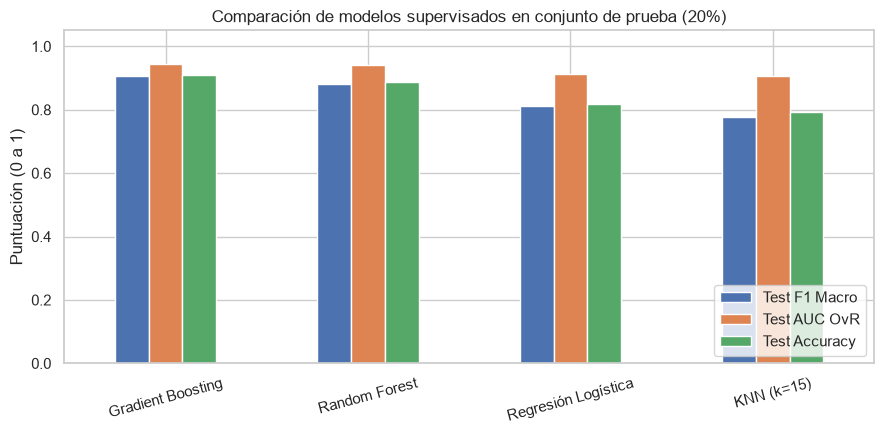

In [25]:
filas_test = []
predicciones_test = {}
probabilidades_test = {}

for nombre, pipe in pipelines_entrenados.items():
    y_pred_train = pipe.predict(X_train)
    y_pred_test = pipe.predict(X_test)
    y_proba_test = pipe.predict_proba(X_test)

    predicciones_test[nombre] = y_pred_test
    probabilidades_test[nombre] = y_proba_test

    f1_tr = f1_score(y_train, y_pred_train, average='macro')
    f1_te = f1_score(y_test, y_pred_test, average='macro')
    auc_te = roc_auc_score(y_test, y_proba_test, multi_class='ovr', average='macro')
    acc_te = accuracy_score(y_test, y_pred_test)

    filas_test.append({
        'Modelo': nombre,
        'Train F1 Macro': f1_tr,
        'Test F1 Macro': f1_te,
        'Brecha (Train - Test)': f1_tr - f1_te,
        'Test AUC OvR': auc_te,
        'Test Accuracy': acc_te,
    })

tabla_comparativa = pd.DataFrame(filas_test).set_index('Modelo').sort_values('Test F1 Macro', ascending=False)
display(tabla_comparativa.round(4))

# Gráfica comparativa de métricas en prueba
fig, ax = plt.subplots(figsize=(9, 4.5))
metricas_plot = tabla_comparativa[['Test F1 Macro', 'Test AUC OvR', 'Test Accuracy']]
metricas_plot.plot.bar(ax=ax)
ax.set_title('Comparación de modelos supervisados en conjunto de prueba (20%)')
ax.set_ylabel('Puntuación (0 a 1)'); ax.set_xlabel('')
ax.set_ylim(0, 1.05)
ax.tick_params(axis='x', rotation=15)
ax.legend(loc='lower right')
fig.tight_layout()
fig.savefig(FIGURAS / 'sup_01_comparacion_modelos.png', dpi=150)
plt.show()

## 6. Selección del mejor modelo, matrices de confusión y análisis de errores
Se selecciona automáticamente el modelo con mayor `Test F1 Macro` (editable en `MODELO_MANUAL`), se despliega su reporte por clase (`Low`, `Medium`, `High`) y se comparan las matrices de confusión de todos los modelos para observar dónde ocurren las confusiones.

Modelo seleccionado: Gradient Boosting
F1 Macro (prueba): 0.9051 | AUC OvR (prueba): 0.9429

Reporte de clasificación por nivel de participación:
              precision    recall  f1-score   support

         Low     0.9126    0.8794    0.8957      2065
      Medium     0.9096    0.9430    0.9260      3875
        High     0.9085    0.8791    0.8935      2067

    accuracy                         0.9101      8007
   macro avg     0.9102    0.9005    0.9051      8007
weighted avg     0.9101    0.9101    0.9098      8007



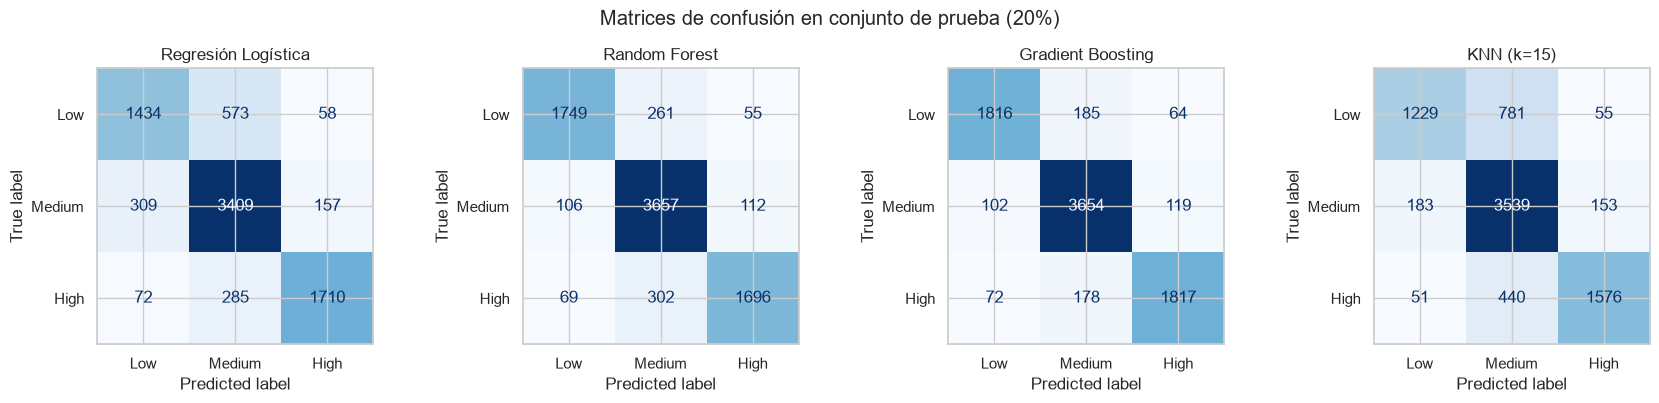

Total de errores en prueba: 720 de 8007 (8.99 %)
Pares de confusión más frecuentes (Real -> Predicho):


casos
Real   Predicho       
Low    Medium      185
High   Medium      178
Medium High        119
       Low         102
High   Low          72
Low    High         64

In [26]:
MODELO_MANUAL = None   # ejemplo: MODELO_MANUAL = 'Gradient Boosting'
MEJOR_NOMBRE = MODELO_MANUAL if MODELO_MANUAL in pipelines_entrenados else tabla_comparativa.index[0]
mejor_modelo = pipelines_entrenados[MEJOR_NOMBRE]
y_pred_mejor = predicciones_test[MEJOR_NOMBRE]

print(f'Modelo seleccionado: {MEJOR_NOMBRE}')
print(f'F1 Macro (prueba): {tabla_comparativa.loc[MEJOR_NOMBRE, "Test F1 Macro"]:.4f} | '
      f'AUC OvR (prueba): {tabla_comparativa.loc[MEJOR_NOMBRE, "Test AUC OvR"]:.4f}')
print('\nReporte de clasificación por nivel de participación:')
print(classification_report(y_test, y_pred_mejor, labels=clases_presentes, digits=4))

# Matrices de confusión de todos los modelos evaluados
n_mod = len(pipelines_entrenados)
fig, ejes = plt.subplots(1, n_mod, figsize=(4.3 * n_mod, 4), squeeze=False)
for eje, (nombre, y_pred) in zip(ejes.flat, predicciones_test.items()):
    cm = confusion_matrix(y_test, y_pred, labels=clases_presentes)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clases_presentes)
    disp.plot(ax=eje, colorbar=False, cmap='Blues')
    eje.set_title(nombre)
fig.suptitle('Matrices de confusión en conjunto de prueba (20%)')
fig.tight_layout()
fig.savefig(FIGURAS / 'sup_02_matrices_confusion.png', dpi=150)
plt.show()

# Análisis de errores en el mejor modelo
errores = X_test.copy()
errores['Real'] = y_test.values
errores['Predicho'] = y_pred_mejor
fallos = errores[errores['Real'] != errores['Predicho']]
print(f'Total de errores en prueba: {len(fallos)} de {len(X_test)} ({len(fallos)/len(X_test)*100:.2f} %)')
if not fallos.empty:
    print('Pares de confusión más frecuentes (Real -> Predicho):')
    display(fallos.groupby(['Real', 'Predicho']).size().sort_values(ascending=False).rename('casos').to_frame())

## 7. Importancia de las variables y conductas que anticipan el abandono
Calculamos la **importancia por permutación** sobre el conjunto de prueba (`permutation_importance`): mide cuánto cae el `F1 Macro` cuando se desordena aleatoriamente cada variable. Este método es agnóstico al modelo y evalúa directamente las columnas originales (antes de *one-hot encoding*).

,Variable,Importancia (caída F1),Desviación
7,SessionsPerWeek,0.4351,0.0048
8,AvgSessionDurationMinutes,0.3584,0.0064
9,PlayerLevel,0.0258,0.0018
10,AchievementsUnlocked,0.0253,0.0016
3,GameGenre,0.0009,0.0004
0,Age,0.0007,0.0006
2,Location,0.0001,0.0003
5,InGamePurchases,0.0000,0.0002
4,PlayTimeHours,-0.0000,0.0008
6,GameDifficulty,-0.0002,0.0003


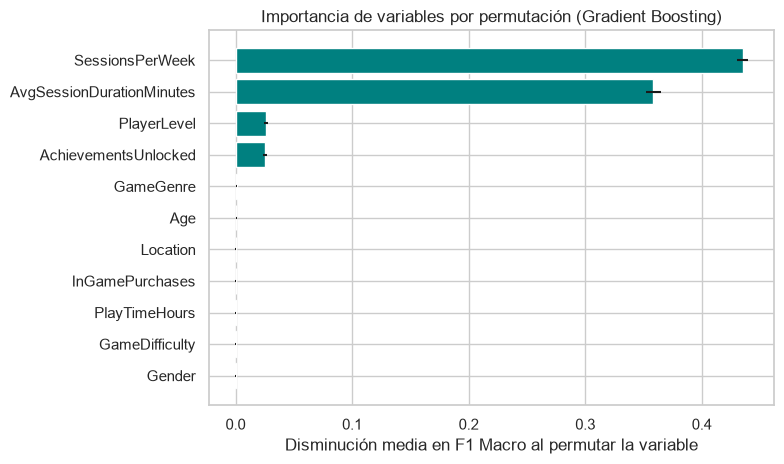

Promedio de las principales variables numéricas por nivel de participación:


,SessionsPerWeek,AvgSessionDurationMinutes,PlayerLevel,AchievementsUnlocked
EngagementLevel,,,,
Low,4.53,66.88,46.10,22.66
Medium,9.55,89.86,50.93,25.22
High,14.25,131.92,50.82,25.10


In [27]:
perm = permutation_importance(
    mejor_modelo, X_test, y_test, scoring='f1_macro', n_repeats=10, random_state=SEMILLA, n_jobs=-1
)
importancias = pd.DataFrame({
    'Variable': X.columns,
    'Importancia (caída F1)': perm.importances_mean,
    'Desviación': perm.importances_std,
}).sort_values('Importancia (caída F1)', ascending=False)

display(importancias.round(4))

fig, ax = plt.subplots(figsize=(8, 4.8))
imp_plot = importancias.sort_values('Importancia (caída F1)', ascending=True)
ax.barh(imp_plot['Variable'], imp_plot['Importancia (caída F1)'], xerr=imp_plot['Desviación'], color='teal')
ax.set_title(f'Importancia de variables por permutación ({MEJOR_NOMBRE})')
ax.set_xlabel('Disminución media en F1 Macro al permutar la variable')
fig.tight_layout()
fig.savefig(FIGURAS / 'sup_03_importancia_variables.png', dpi=150)
plt.show()

# Perfil promedio de las 4 variables principales por clase real
top_vars = [v for v in importancias['Variable'].head(4) if v in cols_numericas]
if top_vars:
    print('Promedio de las principales variables numéricas por nivel de participación:')
    display(df.groupby(OBJETIVO)[top_vars].mean().reindex(clases_presentes).round(2))

## 8. Cruce con estilos del aprendizaje no supervisado (si ya existe el modelo)
Si ya se ejecutó `03_no_supervisado.ipynb`, cargamos `models/kmeans_estilos.joblib` para verificar cómo se distribuyen las predicciones de participación y riesgo de abandono (`Low`) dentro de cada estilo de jugador (`Casual`, `Intensivo`, `Coleccionista`, `Regular`).

In [16]:
ruta_ns = MODELOS / 'kmeans_estilos.joblib'
if ruta_ns.exists():
    artefacto_ns = joblib.load(ruta_ns)
    vars_ns = artefacto_ns['variables']
    grupos_test = artefacto_ns['pipeline'].predict(X_test[vars_ns])
    estilos_test = pd.Series(grupos_test, index=X_test.index).map(artefacto_ns['nombres'])

    cruce_pred = pd.crosstab(estilos_test, pd.Series(y_pred_mejor, index=X_test.index, name='Predicción'), normalize='index') * 100
    cols_ord = [c for c in clases_presentes if c in cruce_pred.columns]
    print('Distribución de participación predicha (%) dentro de cada estilo no supervisado (conjunto de prueba):')
    display(cruce_pred[cols_ord].round(1))
else:
    print('Nota: aún no existe models/kmeans_estilos.joblib (se genera al ejecutar 03_no_supervisado.ipynb).')

Nota: aún no existe models/kmeans_estilos.joblib (se genera al ejecutar 03_no_supervisado.ipynb).


## 9. Guardar el mejor modelo y función de inferencia para el prototipo
Guardamos el `Pipeline` completo en `models/supervisado_participacion.joblib` junto con las columnas esperadas, las métricas en prueba y una función que traduce el nivel predicho (`Low`, `Medium`, `High`) a nivel de riesgo de abandono y recomendación de diseño para `app/app.py`.

In [17]:
RUTA_MODELO_SUP = MODELOS / 'supervisado_participacion.joblib'

RECOMENDACIONES_RIESGO = {
    'Low': {
        'riesgo_abandono': 'Alto riesgo de abandono',
        'accion_diseno': 'Reducir dificultad dinámica, ofrecer recompensas rápidas de bienvenida y sesiones cortas guiadas.',
    },
    'Medium': {
        'riesgo_abandono': 'Riesgo moderado',
        'accion_diseno': 'Mantener curvas de progreso equilibradas, misiones semanales y retroalimentación constante.',
    },
    'High': {
        'riesgo_abandono': 'Bajo riesgo de abandono (alta retención)',
        'accion_diseno': 'Habilitar retos avanzados, eventos competitivos y recompensas por racha para evitar monotonía.',
    },
}

joblib.dump({
    'pipeline': mejor_modelo,
    'nombre_modelo': MEJOR_NOMBRE,
    'columnas_entrada': X.columns.tolist(),
    'columnas_numericas': cols_numericas,
    'columnas_categoricas': cols_categoricas,
    'clases': mejor_modelo.classes_.tolist(),
    'orden_clases': clases_presentes,
    'metricas_test': tabla_comparativa.loc[MEJOR_NOMBRE].to_dict(),
    'recomendaciones': RECOMENDACIONES_RIESGO,
    'semilla': SEMILLA,
}, RUTA_MODELO_SUP)

print('Modelo supervisado guardado en:', RUTA_MODELO_SUP.relative_to(RAIZ))

# Comprobación: recargar el modelo y predecir jugadores nuevos
def predecir_participacion(perfil_jugador: dict, ruta=RUTA_MODELO_SUP):
    artefacto = joblib.load(ruta)
    # Rellena con valores por defecto del dataset si el formulario omite variables secundarias
    base = {col: (X_train[col].median() if col in cols_numericas else X_train[col].mode()[0]) for col in artefacto['columnas_entrada']}
    base.update(perfil_jugador)
    fila = pd.DataFrame([base])[artefacto['columnas_entrada']]

    nivel = str(artefacto['pipeline'].predict(fila)[0])
    probs = dict(zip(artefacto['clases'], np.round(artefacto['pipeline'].predict_proba(fila)[0], 3)))
    info = artefacto['recomendaciones'].get(nivel, {})
    return nivel, info.get('riesgo_abandono', ''), probs, info.get('accion_diseno', '')

ejemplos_prueba = [
    {'PlayTimeHours': 1.5, 'SessionsPerWeek': 2, 'AvgSessionDurationMinutes': 20, 'PlayerLevel': 8, 'InGamePurchases': 0},
    {'PlayTimeHours': 12.0, 'SessionsPerWeek': 7, 'AvgSessionDurationMinutes': 75, 'PlayerLevel': 45, 'InGamePurchases': 0},
    {'PlayTimeHours': 22.0, 'SessionsPerWeek': 15, 'AvgSessionDurationMinutes': 130, 'PlayerLevel': 88, 'InGamePurchases': 1},
]
for ej in ejemplos_prueba:
    nivel, riesgo, probs, _ = predecir_participacion(ej)
    print(f"Horas={ej['PlayTimeHours']}, Sesiones={ej['SessionsPerWeek']}, Nivel={ej['PlayerLevel']} -> {nivel} ({riesgo}) | Probs={probs}")

Modelo supervisado guardado en: models\supervisado_participacion.joblib
Horas=1.5, Sesiones=2, Nivel=8 -> Low (Alto riesgo de abandono) | Probs={'High': np.float64(0.014), 'Low': np.float64(0.975), 'Medium': np.float64(0.011)}
Horas=12.0, Sesiones=7, Nivel=45 -> Medium (Riesgo moderado) | Probs={'High': np.float64(0.027), 'Low': np.float64(0.04), 'Medium': np.float64(0.933)}
Horas=22.0, Sesiones=15, Nivel=88 -> High (Bajo riesgo de abandono (alta retención)) | Probs={'High': np.float64(0.933), 'Low': np.float64(0.026), 'Medium': np.float64(0.041)}


## 10. Interpretación de resultados y decisiones de diseño
Completar con los valores reales obtenidos al ejecutar el cuaderno:

1. **Comparación de algoritmos:** ¿qué modelo obtuvo el mejor `F1 Macro` y `AUC OvR` tanto en validación cruzada (5 particiones) como en prueba (20%)?
2. **Análisis de sobreajuste:** ¿cuál fue la brecha entre `Train F1` y `Test F1` en cada algoritmo (especialmente en Random Forest vs. Gradient Boosting)?
3. **Matriz de confusión y errores:** ¿qué niveles se confunden con mayor frecuencia (por ejemplo, `Medium` con `Low` o `High`) y qué implicación tiene clasificar erróneamente a un jugador `Low`?
4. **Conductas que anticipan el abandono (`Low`):** según la importancia por permutación y los promedios por clase, ¿qué variables pesan más (sesiones por semana, duración media de sesión, nivel o compras)?
5. **Cambio de diseño propuesto:** ¿qué ajuste concreto en el videojuego (dificultad adaptativa, misiones cortas o recompensas tempranas) se probaría para retener a los jugadores detectados en nivel `Low`?